# General

All project work in IND320 will result in personal hand-ins and online apps.

### 1. Jupyter Notebook

A Jupyter Notebook run locally on your computer, later with access to online and local databases.

This will be your basic development and documentation platform.

#### Required content

- A brief description of AI usage.
- A 300–500-word log describing the compulsory work, including both Jupyter Notebook and Streamlit experience.
- Links to your public GitHub repository and Streamlit app for the compulsory work.

#### Documentation and submission

- Document headings should be clear and usable for navigation during development.
- All code blocks must include enough comments to be understandable and reproducible if someone inherits your project.
- All code blocks must be run before exporting to PDF so that messages and plots are shown.
- Add the `.ipynb` file to the GitHub repository containing your Streamlit project.

### 2. Streamlit App

A Streamlit app running at `https://[yourproject].streamlit.app/`.

- This will be an online version of the project, accessing data exported to CSV format and, later, an online database.
- The code must be hosted on GitHub.
- The code must include relevant comments from the Jupyter Notebook and additional comments regarding Streamlit usage.

#### Project Structure and Collaboration

- There are four parts in the project work, building on each other and resulting in a final portfolio and app to be presented at the end of the semester.
- Cooperation is applauded, and the use of AI tools is encouraged.

## Tasks

### GitHub and Streamlit.app accounts

- GitHub: https://github.com/danielytsan/IND320APP
- Steamlit: https://ind320app-s2bytfwvqxbzmwkxrm2aze.streamlit.app

# Presentation link

 Due to the video file being to large for github I have choosen to upload it to youtube. Use this link to access it:

https://youtu.be/zhCRaJ-9PeA


## AI usage
AI has been used during development of the content provided for this app and Jupyter Notebook

The model I have been using is ChatGPT-6.1 Sol to:
- debugging and suggestion for code with error messages
- learning streamlit and different function
- learing to use api keys and how to format the files for it. Specially for how to use the token on Entso-e.
- help with using spark
- Used for helping with merge conflict
- some guidens on explaining the concept of the task

# Jupyter Notebook
* Navigate to https://atlas.nve.no to locate and download the shapefiles corresponding to the electricity areas and precipitation areas that correspond to the Magasinstatistikk data. Note: East is split into RS+RØ, and North is split into RM+RN.
    * Randomly sample 1000 locations in each region to use for weather data download.

* Use the open-meteo API to retrieve hourly historical reanalysis data using the ERA5 model for a single location as follows:
    * Create a function for the API download task that takes a region identifier plus a time interval as input, looks up the corresponding list of pairs of longitude and latitude values and downloads at least precipitation and temperature, but include any relevant property you find.

    * Apply the function to download data for NO3 for 2024.

* Outliers and anomalies:
    * Plot the average precipitation as a function of time.
        * Perform a high-pass filtering of the precipitation using the Discrete Cosine Transform to create seasonally adjusted temperature variations (SATV).
        
        * Add curves to the plot indicating Statistical Process Control boundaries between inliers and outliers based on the SATV according to robust statistics estimated from the whole year. Colour outliers with a contrasting colour. Do not plot SATV values; only use them to find boundaries and outliers.
        
        * Let the frequency cut-off for the DCT and the number of standard deviations be parameters with sensible defaults.
        
        * Wrap this in a function that returns the plot and relevant summaries of the outliers, and test the function.

    * Plot the average temperature as a function of time.
        * Indicate anomalies according to the Local Outlier Factor method.
        
        * Let the proportion of outliers be a parameter defaulting to 1%.

        * Wrap this in a function that returns the plot and relevant summaries of the outliers, and test the function.

* Seasonal-Trend decomposition using LOESS (STL)
    * Perform STL on the degree of filling from the magasinstatistikk data and plot its decomposition.
    
    * Let the seasonal smoother, trend smoother and robust (true/false) be parameters, and give each of them sensible defaults.
    
    * Wrap this in a function that returns the plot, and test the function.

* Spectrogram
    * Create a spectrogram based on the same data.
    
    * Let the window length and window overlap be parameters, and give each of them sensible defaults.
    
    * Wrap this in a function that returns the plot, and test the function.

In [78]:
#importing libraries
import openmeteo_requests
import pandas as pd
import requests_cache
from retry_requests import retry
import geopandas as gpd
from pathlib import Path
import matplotlib.pyplot as plt
from scipy.fft import dct, idct
from scipy.stats import median_abs_deviation
from sklearn.neighbors import LocalOutlierFactor
import numpy as np

secrets = {}

with open("../.streamlit/secrets.toml", "r") as file:
    for line in file:
        line = line.strip()

        #Skip empty lines and comments
        if not line or line.startswith("#"):
            continue

        name, value = line.split("=", 1)
        secrets[name.strip()] = value.strip()

meteo_url = secrets["meteo_url"]

* Navigate to https://atlas.nve.no to locate and download the shapefiles corresponding to the electricity areas and precipitation areas that correspond to the Magasinstatistikk data. Note: East is split into RS+RØ, and North is split into RM+RN.
    * Randomly sample 1000 locations in each region to use for weather data download.

In [33]:
#reading the shp. file from atlas-nve.no
gdf = gpd.read_file("../data/NVE_Region/NVE_Region.shp", encoding = "utf-8")

old_region = gdf['REGION'].astype(str).str.strip().str.upper()
gdf['NEW_REGION'] = old_region.replace({
    'RS': 'RE',
    'RØ': 'RE',
    'RM': 'RMN',
    'RN': 'RMN',
})

gdf = gdf[['NEW_REGION', 'geometry']].dissolve(by = 'NEW_REGION')

#generating 1000 random points within each region of the shapefile
k = 1000
points_per_region = gdf['geometry'].sample_points(size = k, random_state = 42)

#transfor WGS84 for latidue and longitude
points_wgs84 = points_per_region.to_crs(epsg = 4326)

#extracting latitude and longitude from the points
for index, multipoint in points_wgs84.items():
    region_name = index
    print(f"Region: {region_name}")

    for point in multipoint.geoms:
        latitude = point.y
        longitude = point.x

region_location = {
    region_name: [(point.y, point.x) for point in multipoint.geoms]
    for region_name, multipoint in points_wgs84.items()
}

for region, location in region_location.items():
    print(region, len(location))


Region: RE
Region: RMN
Region: RV
RE 1000
RMN 1000
RV 1000


* Use the open-meteo API to retrieve hourly historical reanalysis data using the ERA5 model for a single location as follows:
    * Create a function for the API download task that takes a region identifier plus a time interval as input, looks up the corresponding list of pairs of longitude and latitude values and downloads at least precipitation and temperature, but include any relevant property you find.

    * Apply the function to download data for NO3 for 2024.

In [ ]:
#Budområder
areas = gpd.read_file("../data/Budområder/Budområder.shp")
labels = areas["budomr"].str.replace(r"\s", "", regex = True)

#matcher regioner på budområdet for NO3
no3 = areas.loc[labels == "NO3"].copy()
no3 = no3.dissolve().to_crs(epsg = 3035)
no3_points = no3.geometry.sample_points(size = k, random_state = 42)
#converts to langitude and latitude
no3_points = no3_points.to_crs(epsg = 4326)

region_location["NO3"] = [(point.y, point.x) for multipoint in no3_points for point in multipoint.geoms]

In [ ]:
# Setup the Open-Meteo API client with cache and retry on error
cache_session = requests_cache.CachedSession('.cache', expire_after = 3600)
retry_session = retry(cache_session, retries = 5, backoff_factor = 0.2)
openmeteo = openmeteo_requests.Client(session = retry_session)

#making a function to download weather data for a given region and date range
def download_weather_data(region, start_date, end_date):
	
	variables = [
        "temperature_2m",
        "precipitation",
        "snowfall",
	]
	results = []

	#looping through the points in the region and downloading the weather data for each point
	for point_id, (latitude, longitude) in enumerate(region_location[region], start = 1):
		params = {
			"latitude": latitude,
			"longitude": longitude,
			"start_date": start_date,
			"end_date": end_date,
			"hourly": variables,
            "models": "era5",
            "timezone": "GMT",
		}

		response = openmeteo.weather_api(meteo_url, params = params)[0]
		hourly = response.Hourly()

		#creating a dataframe with the weather data for the point
		data = {
            "time": pd.date_range(
                 start = pd.to_datetime(hourly.Time(), unit = "s", utc = True),
				 end = pd.to_datetime(hourly.TimeEnd(), unit = "s", utc = True),
                 freq = pd.Timedelta(seconds = hourly.Interval()),
                 inclusive = "left",	
			)
		}

		for i, variable in enumerate(variables):
			data[variable] = hourly.Variables(i).ValuesAsNumpy()

		weather = pd.DataFrame(data)
		weather["region"] = region
		weather["point_id"] = point_id
		weather["latitude"] = latitude
		weather["longitude"] = longitude
		results.append(weather)
		print(f"{region}: {point_id}/{len(region_location[region])} location")

	return pd.concat(results, ignore_index = True)

In [ ]:
#####IKKE KJØR KODEN IGJEN
#using function to download data from NO3 for 2024
Path("../data/.weather_data").mkdir(parents = True, exist_ok = True)

no3_weather = download_weather_data("NO3", "2024-01-01", "2024-12-31")
no3_weather.to_csv("../data/.weather_data/no3_weather_2024.csv", index = False)
print(no3_weather.head())

NO3: 1/1000 location
NO3: 2/1000 location
NO3: 3/1000 location
NO3: 4/1000 location
NO3: 5/1000 location
NO3: 6/1000 location
NO3: 7/1000 location
NO3: 8/1000 location
NO3: 9/1000 location
NO3: 10/1000 location
NO3: 11/1000 location
NO3: 12/1000 location
NO3: 13/1000 location
NO3: 14/1000 location
NO3: 15/1000 location
NO3: 16/1000 location
NO3: 17/1000 location
NO3: 18/1000 location
NO3: 19/1000 location
NO3: 20/1000 location
NO3: 21/1000 location
NO3: 22/1000 location
NO3: 23/1000 location
NO3: 24/1000 location
NO3: 25/1000 location
NO3: 26/1000 location
NO3: 27/1000 location
NO3: 28/1000 location
NO3: 29/1000 location
NO3: 30/1000 location
NO3: 31/1000 location
NO3: 32/1000 location
NO3: 33/1000 location
NO3: 34/1000 location
NO3: 35/1000 location
NO3: 36/1000 location
NO3: 37/1000 location
NO3: 38/1000 location
NO3: 39/1000 location
NO3: 40/1000 location
NO3: 41/1000 location
NO3: 42/1000 location
NO3: 43/1000 location
NO3: 44/1000 location
NO3: 45/1000 location
NO3: 46/1000 locati

* Outliers and anomalies:
    * Plot the average precipitation as a function of time.
        * Perform a high-pass filtering of the precipitation using the Discrete Cosine Transform to create seasonally adjusted temperature variations (SATV).
        
        * Add curves to the plot indicating Statistical Process Control boundaries between inliers and outliers based on the SATV according to robust statistics estimated from the whole year. Colour outliers with a contrasting colour. Do not plot SATV values; only use them to find boundaries and outliers.
        
        * Let the frequency cut-off for the DCT and the number of standard deviations be parameters with sensible defaults.
        
        * Wrap this in a function that returns the plot and relevant summaries of the outliers, and test the function.

    * Plot the average temperature as a function of time.
        * Indicate anomalies according to the Local Outlier Factor method.
        
        * Let the proportion of outliers be a parameter defaulting to 1%.

        * Wrap this in a function that returns the plot and relevant summaries of the outliers, and test the function.

Test passed :)
total_hours            8784.000000
outliers_hours          652.000000
outliers_percentage       7.422587
upper_outliers          652.000000
lower_outliers            0.000000
robust_std                0.163125
cutoff_days              30.000000
n_std                     3.000000
dtype: float64
                           precipitation  lower_bound  upper_bound  \
time                                                                 
2024-01-12 20:00:00+00:00         0.6713    -0.376932     0.601819   
2024-01-12 21:00:00+00:00         0.9275    -0.376130     0.602620   
2024-01-12 22:00:00+00:00         1.1078    -0.375328     0.603422   
2024-01-12 23:00:00+00:00         1.2784    -0.374524     0.604226   
2024-01-13 00:00:00+00:00         1.3365    -0.373719     0.605031   

                           robust_score  is_outlier direction  
time                                                           
2024-01-12 20:00:00+00:00      3.425938        True     above  
2024-01

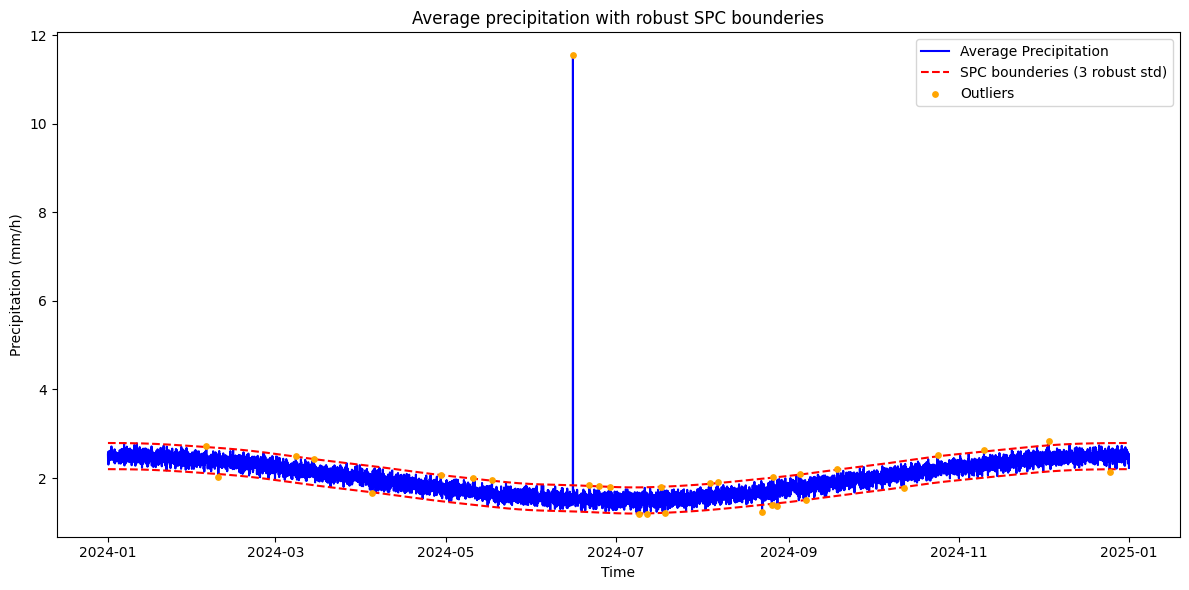

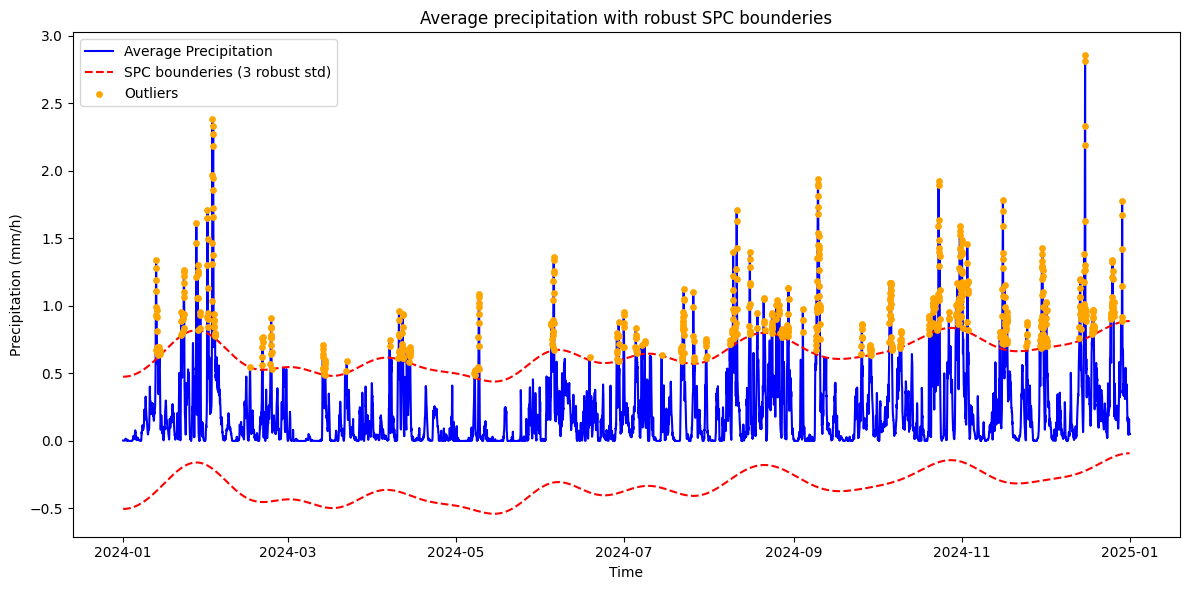

In [ ]:
#making ha function to plot the average precipitation

def plot_precipitation_outliers(weather, cutoff_days = 30, n_std = 3):
    data = weather[["time", "precipitation"]].copy()
    data["time"] = pd.to_datetime(data["time"], utc = True)

    #sort timestamps so it is in chronological order
    precipitation = (data.groupby("time")["precipitation"].mean().sort_index())

    #create a date range with the same start and end times as the precipitation data
    expected_time = pd.date_range(precipitation.index.min(), precipitation.index.max(), freq = "h",)

    y = precipitation.to_numpy(dtype = float)

    #dct convert signal to cosine coefficients
    fourier_signal = dct(y, type = 1, norm = "forward")

    w = np.linspace(0, .5, len(y))
    cutoff_frequency = 1 / (cutoff_days * 24)

    #highpass filter to remove mean and low frequency variations
    filtered_signal = fourier_signal.copy()
    filtered_signal[w <= cutoff_frequency] = 0

    #inverse transfrom
    satv = idct(filtered_signal, type = 1, norm = "forward")
    trend = y - satv

    #outlier detection using robust statistics
    center = np.median(satv)
    robust_std = 1.4826 * median_abs_deviation(satv)

    #precipitation values
    lower = trend + center - n_std * robust_std
    upper = trend + center + n_std * robust_std
    is_outlier = (y < lower) | (y > upper)

    #
    results = pd.DataFrame({
        "precipitation": y,
        "lower_bound": lower,
        "upper_bound": upper,
        "robust_score": (satv - center) / robust_std,
        "is_outlier": is_outlier,
    }, index = precipitation.index)
    results.index.name = "time"
    outliers = results.loc[is_outlier].copy()
    outliers["direction"] = np.where(outliers["precipitation"] > outliers["upper_bound"], "above", "below")

    #sum
    summary = pd.Series({
        "total_hours": len(y),
        "outliers_hours": int(is_outlier.sum()),
        "outliers_percentage": 100 * is_outlier.mean(),
        "upper_outliers": int((y > upper).sum()),
        "lower_outliers": int((y < lower).sum()),
        "robust_std": robust_std,
        "cutoff_days": cutoff_days,
        "n_std": n_std,
    })

    #plotting precipitation, SPC boundaries and contrasting ouliers markers
    fig, ax = plt.subplots(figsize = (12, 6))
    ax.plot(precipitation.index, y, color = "blue", label = "Average Precipitation")
    ax.plot(precipitation.index, upper, color = "red", linestyle = "--", label = f"SPC bounderies ({n_std} robust std)")
    ax.plot(precipitation.index, lower, color = "red", linestyle = "--")
    ax.scatter(outliers.index, outliers["precipitation"], color = "orange", label = "Outliers", zorder = 3, s = 15)
    ax.set_title(f"Average precipitation with robust SPC bounderies")
    ax.set_xlabel("Time")
    ax.set_ylabel("Precipitation (mm/h)")
    ax.legend()
    fig.tight_layout()

    return fig, summary, outliers

#test the function with a year contating a know spike
def test_precipitation_plot():
    rng = np.random.default_rng(42)
    time = pd.date_range("2024-01-01", "2025-01-01", freq = "h", inclusive = "left", tz = "UTC")

    #seasonal cosine signal
    x = np.arange(len(time))
    y = (2 + .5 *np.cos(2 * np.pi * x / len(time))) + rng.normal(0, .1, len(time))

    #adding a spike
    spike = 4000
    y[spike] += 10

    #two location ehere hourly mean is y
    test_data = pd.concat([
        pd.DataFrame({"time": time, "precipitation": y - 0.1}),
        pd.DataFrame({"time": time, "precipitation": y + 0.1})
    ], ignore_index = True)

    fig, summary, outliers = plot_precipitation_outliers(test_data)

    #checking hourly avarage and detection of the added spike
    assert summary["total_hours"] == 8784
    assert time[spike] in outliers.index
    assert outliers.loc[time[spike], "direction"] == "above"
    assert np.isclose(outliers.loc[time[spike], "precipitation"], y[spike])
    wider_fig, wider_summary, _ = plot_precipitation_outliers(test_data, n_std = 5)
    assert wider_summary["outliers_hours"] <= summary["outliers_hours"]

    plt.close()
    plt.close(wider_fig)

#running the test
test_precipitation_plot()

#applying the function to the full year of NO3 weather data
fig, summary, outliers = plot_precipitation_outliers(no3_weather, cutoff_days = 30, n_std = 3)
print(summary)
print(outliers.head())
plt.show()

                           temperature_2m  LOF_score  is_outlier
time                                                            
2024-01-03 09:00:00+00:00       -9.525029   1.223610        True
2024-01-03 21:00:00+00:00      -10.336130   1.220784        True
2024-01-04 14:00:00+00:00      -10.322929   1.211401        True
2024-01-23 17:00:00+00:00        0.649471   1.208702        True
2024-02-08 00:00:00+00:00       -9.459829   1.212690        True


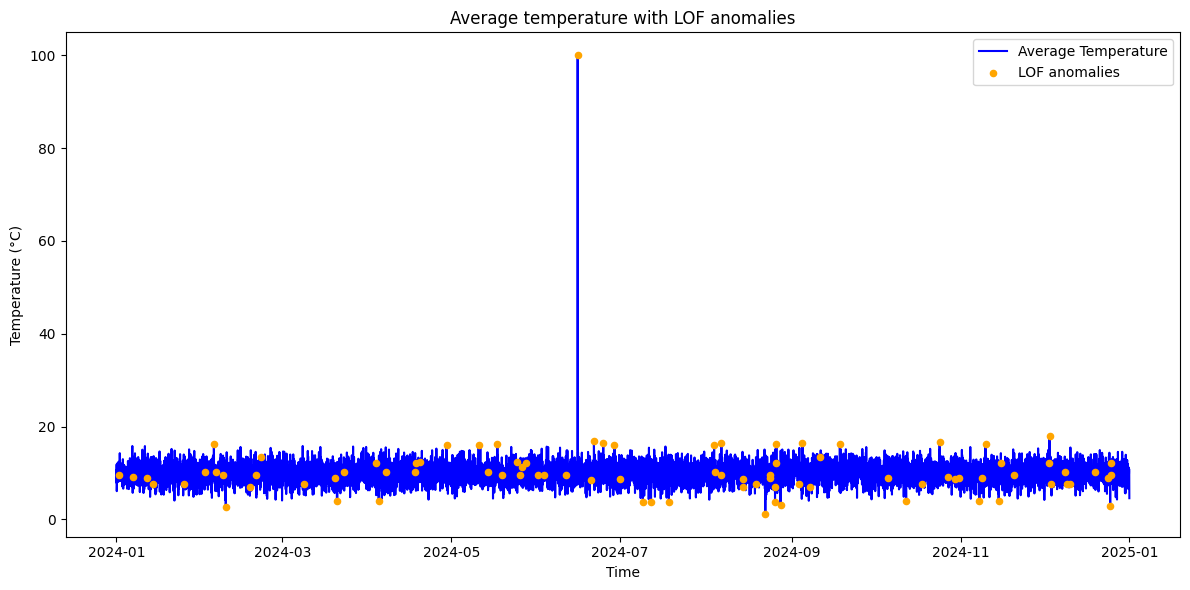

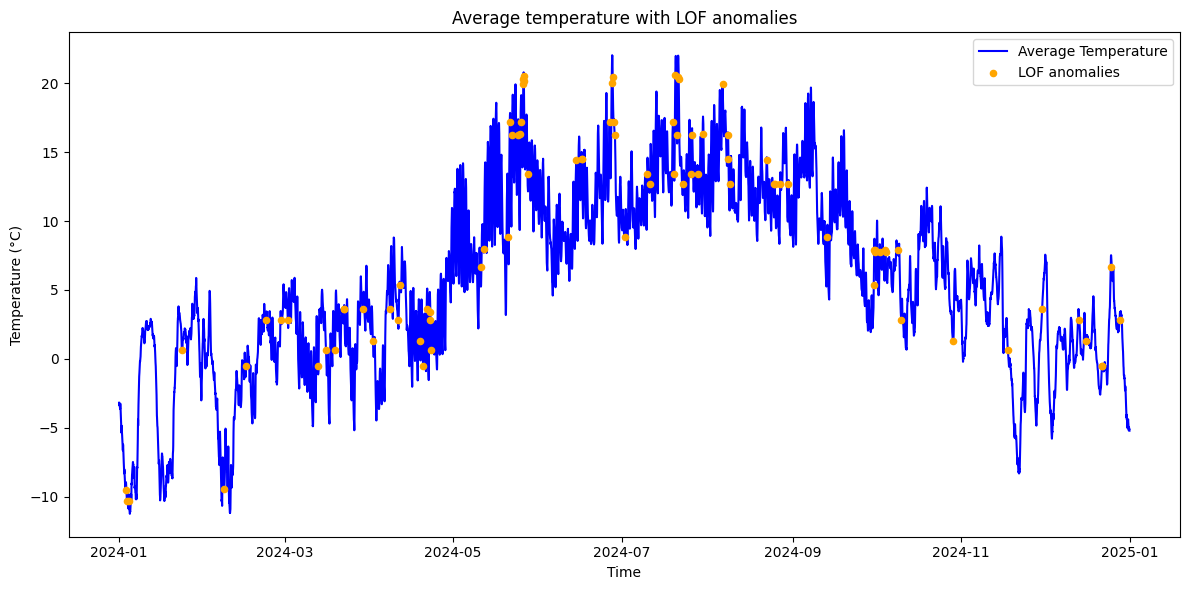

In [82]:
# making a function to plot the average temperature of time
def plot_temperature_outliers(weather, outlier_proportion = 0.01):
    data = weather[["time", "temperature_2m"]].copy()
    data["time"] = pd.to_datetime(data["time"], utc = True)

    temperature = data.groupby("time")["temperature_2m"].mean().sort_index()
    values = temperature.to_numpy(dtype = float)

    #local outlier factor requires 2d array
    X = values.reshape(-1, 1)

    #comparing each density with the nearest neighbor
    lof = LocalOutlierFactor(n_neighbors = 20, contamination = outlier_proportion)
    lables = lof.fit_predict(X)
    is_outlier = lables == -1
    scores = -lof.negative_outlier_factor_
    results = pd.DataFrame({
        "temperature_2m": values,
        "LOF_score": scores,
        "is_outlier": is_outlier,
    }, index = temperature.index)
    results.index.name = "time"
    outliers = results.loc[is_outlier].copy()

    summary = pd.Series({
        "total_hours": len(values),
        "outliers_hours": int(is_outlier.sum()),
        "outliers_percentage": 100 * is_outlier.mean(),
        "requested_outlier_percentage": 100 * outlier_proportion,
        "minimum_outlier_temp": outliers["temperature_2m"].min(),
        "maximum_outlier_temp": outliers["temperature_2m"].max(),
        "maximum_lof_score": scores.max(),
    })

    #plotting temperature and marking anomalous hours
    fig, ax = plt.subplots(figsize = (12, 6))
    ax.plot(temperature.index, values, color = "blue", label = "Average Temperature")
    ax.scatter(outliers.index, outliers["temperature_2m"], color = "orange", s = 20, zorder = 3, label = "LOF anomalies")
    ax.set_title("Average temperature with LOF anomalies")
    ax.set_xlabel("Time")
    ax.set_ylabel("Temperature (°C)")
    ax.legend()
    fig.tight_layout()

    return fig, summary, outliers

#testing the function
def test_temperature_plot():
    rng = np.random.default_rng(42)
    time = pd.date_range("2024-01-01", "2025-01-01", freq = "h", inclusive = "left", tz = "UTC")

    values = rng.normal(10, 2, len(time))

    #inserting a spike
    spike = 4000
    values[spike] = 100

    test_data = pd.concat([
        pd.DataFrame({"time": time, "temperature_2m": values - .5}),
        pd.DataFrame({"time": time, "temperature_2m": values + .5})
    ], ignore_index = True)

    fig, summary, outliers = plot_temperature_outliers(test_data)

    assert summary["total_hours"] == 8784
    assert time[spike] in outliers.index
    assert np.isclose(outliers.loc[time[spike], "temperature_2m"], 100)

    #the flaged proportion should be approximately 1%
    assert abs(summary["outliers_percentage"] - 1) < .5
    more_fig, more_summary, _ = plot_temperature_outliers(test_data, outlier_proportion = 0.02)
    assert more_summary["outliers_hours"] >= summary["outliers_hours"]

    plt.close()
    plt.close(more_fig)

#running the test
test_temperature_plot()

#Applying the function to NO3 weather data
fig, summary, outliers = plot_temperature_outliers(no3_weather, outlier_proportion = 0.01)
print(outliers.head())
plt.show()


* Seasonal-Trend decomposition using LOESS (STL)
    * Perform STL on the degree of filling from the magasinstatistikk data and plot its decomposition.
    
    * Let the seasonal smoother, trend smoother and robust (true/false) be parameters, and give each of them sensible defaults.
    
    * Wrap this in a function that returns the plot, and test the function.

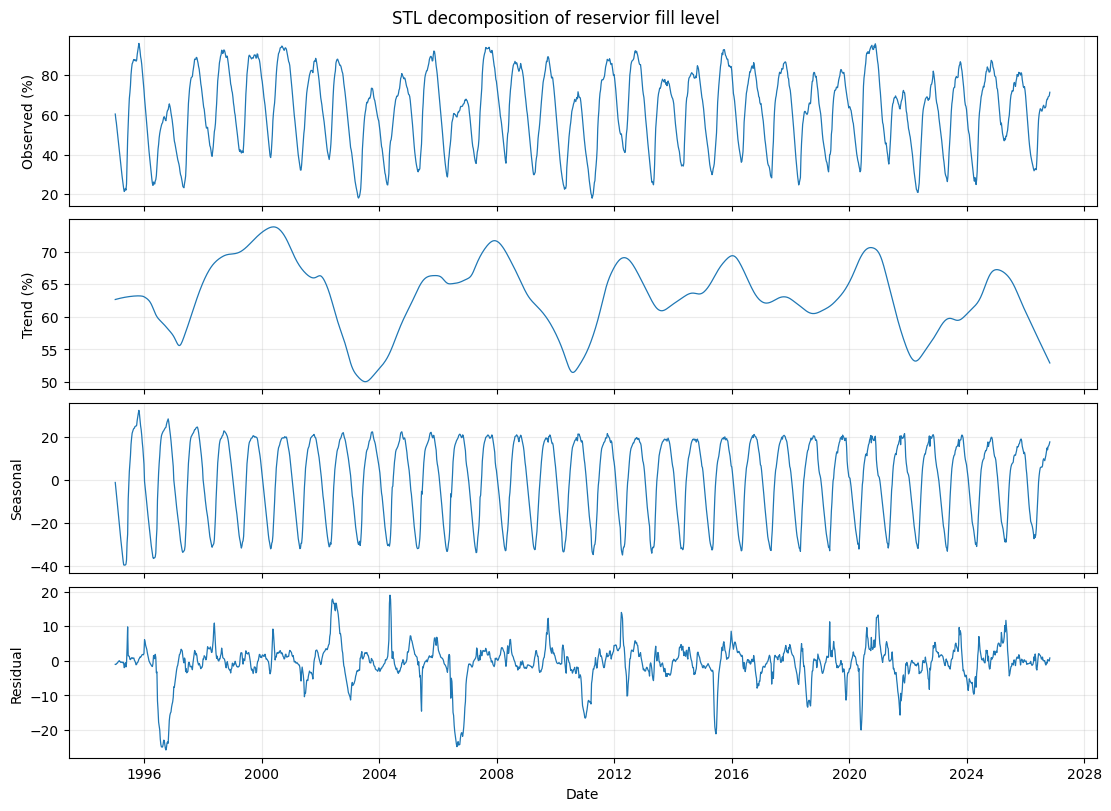

In [108]:
from statsmodels.tsa.seasonal import STL
import requests

#importing data form magasinstatistikk through API url and converting it into a pandas dataframe
response = requests.get(secrets["magasinstatistikk_url"], timeout = 30)
response.raise_for_status()

df = pd.DataFrame(response.json())

#changing the names on the columns
df = df.rename(columns = {
    "dato_Id": "Date", 
    "omrType": "Area", 
    "omrnr": "Area number",
    "fyllingsgrad": "Fill level",
})

#converting the date column to datetime and sorting the dataframe by date in descending order
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values(by="Date", ascending=False)

df["Area label"] = (df["Area"] + " " + df["Area number"].astype(str))

#creating new columns for fill level in percentage
df["Fill level (%)"] = df["Fill level"] * 100

#making the function to perform STL on magasinstatistik data
#I was not sure which area to use so i selected NO0
def plot_fill_stl(df, seasonal = 7, trend = 101, robust = True, *, area = "NO 0"):
    #using the area and sorting
    fill = (df.loc[df["Area label"].eq(area)]
            .set_index("Date")["Fill level (%)"]
            .sort_index()
            .asfreq("W-SUN"))

    result = STL(
        fill, 
        period = 52,
        seasonal = seasonal,
        trend = trend,
        robust = robust
    ).fit()

    fig, axes = plt.subplots(
        4,
        1,
        sharex = True,
        figsize = (11, 8),
        layout = "constrained"
    )

    for ax, values, label in zip(
        axes,
        (result.observed, result.trend, result.seasonal, result.resid),
        ("Observed (%)", "Trend (%)", "Seasonal", "Residual")
    ):
        ax.plot(values.index, values, linewidth = .9)
        ax.set_ylabel(label)
        ax.grid(alpha = .25)

    axes[-1].set_xlabel("Date")
    fig.suptitle("STL decomposition of reservior fill level")
    return fig

#testing the function and returning the plot
original_fig = plot_fill_stl(df)
changed_fig = plot_fill_stl(df, seasonal = 13, trend = 79, robust = False)

for fig in (original_fig, changed_fig):
    assert len(fig.axes) == 4
    observed, trend, seasonal, residual = [
        ax.lines[0].get_ydata() for ax in fig.axes
    ]
    np.testing.assert_allclose(
        observed, trend + seasonal + residual
    )

plt.close(changed_fig)
plt.show()

* Spectrogram
    * Create a spectrogram based on the same data.
    
    * Let the window length and window overlap be parameters, and give each of them sensible defaults.
    
    * Wrap this in a function that returns the plot, and test the function.

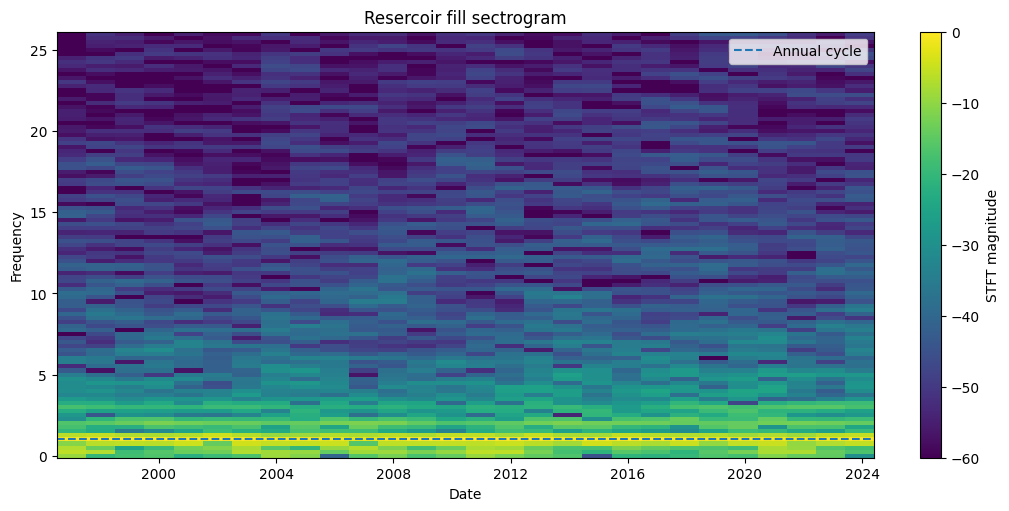

In [ ]:
from scipy.signal import stft

#making function for spectogram based on fill level data
def plot_fill_spectrogram(data, window_length = 208, window_overlap = 156):
    fill = (
            data.set_index("Date")["Fill level (%)"]
            .sort_index()
            .asfreq("W-SUN"))

    frequncies, weeks, coefficients = stft(
        fill.to_numpy(),
        fs = 1,
        nperseg = window_length,
        noverlap = window_overlap,
        detrend = "constant",
        boundary = None,
        padded = False
    )

    dates = fill.index[0] + pd.to_timedelta(weeks * 7, unit = "D")
    fig, ax = plt.subplots(figsize = (10, 5), layout = "constrained")

    #to be able to see the plot more clearer i have added a dB scale so it is easier to see variation on the higher frequencies
    magnitude = np.abs(coefficients)
    peak = magnitude.max()
    reference = peak if peak > 0 else 1.0
    magnitude_db = 20 * np.log10(np.maximum(magnitude / reference, 1e-12))

    mesh = ax.pcolormesh(dates, frequncies * 52, magnitude_db, shading = "auto", vmin = -60, vmax = 0)
    ax.axhline(1, linestyle = "--", label = "Annual cycle")
    ax.set(
        title = "Resercoir fill sectrogram",
        xlabel = "Date",
        ylabel = "Frequency"
    )
    ax.legend()
    fig.colorbar(mesh, ax = ax, label = "STFT magnitude")
    return fig

#making a test for the function og returning the plot
fig = plot_fill_spectrogram(df.loc[df["Area label"] == "NO 0"])

assert isinstance(fig, plt.Figure)
assert len(fig.axes[0].collections) == 1
magnitudes = fig.axes[0].collections[0].get_array()
assert magnitudes.size > 0
assert np.isfinite(magnitudes).all()
plt.show()

## Description of the compulsory work